![Banner](./img/AI_Special_Program_Banner.jpg)  

# Day 3 Exercises for Data Cleaning and Aggregation of data
---

In this exercise, you are to reconstruct an analysis by [David Robinson](http://varianceexplained.org/r/tidy-genomics/) in Python/Pandas. In this analysis, David Robinson analyzed the dataset `./data/Brauer2008_DataSet1.tds` from [Brauer 2008](https://www.molbiolcell.org/doi/full/10.1091/mbc.e07-08-0779) on **gene expression in yeast cultures** using. Your task is to **convert the dataset into a tidy data format**. This should allow the data to be easily filtered and visualized.

In [6]:
import pandas as pd
df_gene = pd.read_csv('./data/Brauer2008_DataSet1.tds', delimiter='\t')
df_gene.head()

,GID,YORF,NAME,GWEIGHT,G0.05,G0.1,G0.15,G0.2,G0.25,G0.3,...,L0.15,L0.2,L0.25,L0.3,U0.05,U0.1,U0.15,U0.2,U0.25,U0.3
0,GENE1331X,A_06_P5820,SFB2 || ER to Golgi transport || molecul...,1,-0.24,-0.13,-0.21,-0.15,-0.05,-0.05,...,0.13,0.20,0.17,0.11,-0.06,-0.26,-0.05,-0.28,-0.19,0.09
1,GENE4924X,A_06_P5866,|| biological process unknown || mol...,1,0.28,0.13,-0.40,-0.48,-0.11,0.17,...,0.02,0.04,0.03,0.01,-1.02,-0.91,-0.59,-0.61,-0.17,0.18
2,GENE4690X,A_06_P1834,QRI7 || proteolysis and peptidolysis || ...,1,-0.02,-0.27,-0.27,-0.02,0.24,0.25,...,-0.07,-0.05,-0.13,-0.04,-0.91,-0.94,-0.42,-0.36,-0.49,-0.47
3,GENE1177X,A_06_P4928,CFT2 || mRNA polyadenylylation* || RNA b...,1,-0.33,-0.41,-0.24,-0.03,-0.03,0.00,...,-0.05,0.02,0.00,0.08,-0.53,-0.51,-0.26,0.05,-0.14,-0.01
4,GENE511X,A_06_P5620,SSO2 || vesicle fusion* || t-SNARE activ...,1,0.05,0.02,0.40,0.34,-0.13,-0.14,...,0.00,-0.11,0.04,0.01,-0.45,-0.09,-0.13,0.02,-0.09,-0.03


Specifically, the following **problems** need to be solved:

* **Column names are values and not variables** The column names contain values for two variables: *Nutrient* (G,N,P, etc.) and *Growth Rate* (0.05-0.3). This means that we do not get one observation per row, but 36! This is a common problem in biological data; due to the high dimensionality, you often see one row per gene and one row per sample, instead of one row per gene per sample.
* **Multiple variables are stored in one column** The column `NAME` contains a lot of information, separated by `||`. More precisely, it contains information for:
    * Name of the gene e.g. SFB2. However, not all genes have a name
    * Biological process e.g. "proteolysis and peptidolysis"
    * Molecular function e.g. "metalloendopeptidase activity"
    * Systematic ID e.g. YNL049C. Each gene in this dataset has such an ID
    * Another ID e.g. 1082129. Unfortunately it is not known what this ID represents.

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df_gene = pd.read_csv('./data/Brauer2008_DataSet1.tds', delimiter='\t')

name_split = df_gene['NAME'].str.split(r'\|\|', expand=True)

df_gene['Gene_Name'] = name_split[0].str.strip()
df_gene['Biological_Process'] = name_split[1].str.strip()
df_gene['Molecular_Function'] = name_split[2].str.strip()
df_gene['Systematic_ID'] = name_split[3].str.strip()
df_gene['Other_ID'] = name_split[4].str.strip()

df_gene = df_gene.drop('NAME', axis=1)

id_vars = ['GID', 'YORF', 'GWEIGHT', 'Gene_Name', 'Biological_Process', 
           'Molecular_Function', 'Systematic_ID', 'Other_ID']

df_tidy = df_gene.melt(id_vars=id_vars, var_name='Sample', value_name='Expression')

df_tidy['Nutrient'] = df_tidy['Sample'].str[0]
df_tidy['Growth_Rate'] = df_tidy['Sample'].str[1:].astype(float)

nutrient_map = {'G': 'Glucose', 'L': 'Leucine', 'P': 'Phosphate', 
                'S': 'Sulfate', 'N': 'Ammonia', 'U': 'Uracil'}
df_tidy['Nutrient_Name'] = df_tidy['Nutrient'].map(nutrient_map)

df_tidy = df_tidy.drop('Sample', axis=1)

display(df_tidy.head())

,GID,YORF,GWEIGHT,Gene_Name,Biological_Process,Molecular_Function,Systematic_ID,Other_ID,Expression,Nutrient,Growth_Rate,Nutrient_Name
0,GENE1331X,A_06_P5820,1,SFB2,ER to Golgi transport,molecular function unknown,YNL049C,1082129,-0.24,G,0.05,Glucose
1,GENE4924X,A_06_P5866,1,,biological process unknown,molecular function unknown,YNL095C,1086222,0.28,G,0.05,Glucose
2,GENE4690X,A_06_P1834,1,QRI7,proteolysis and peptidolysis,metalloendopeptidase activity,YDL104C,1085955,-0.02,G,0.05,Glucose
3,GENE1177X,A_06_P4928,1,CFT2,mRNA polyadenylylation*,RNA binding,YLR115W,1081958,-0.33,G,0.05,Glucose
4,GENE511X,A_06_P5620,1,SSO2,vesicle fusion*,t-SNARE activity,YMR183C,1081214,0.05,G,0.05,Glucose


### Bonus task

Also implement the **visualization** for the nutrient `name=='LEU1'` and biological process `BP=='leucine biosynthesis'`in Python! Since the plotting capabilities of Pandas are probably not sufficient here, you should take a look at [seaborn](https://seaborn.pydata.org/). The first plot should be quite easy to solve with `sns.lineplot`. For the second plot you need to use a [FacetGrid](https://seaborn.pydata.org/generated/seaborn.FacetGrid.html).

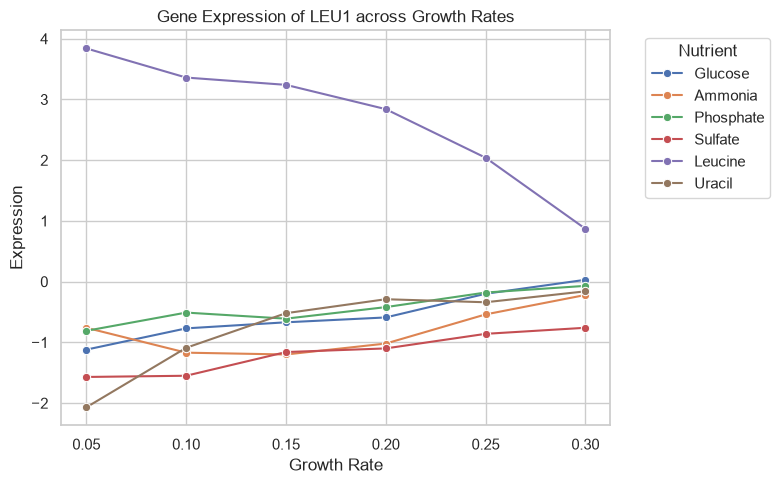

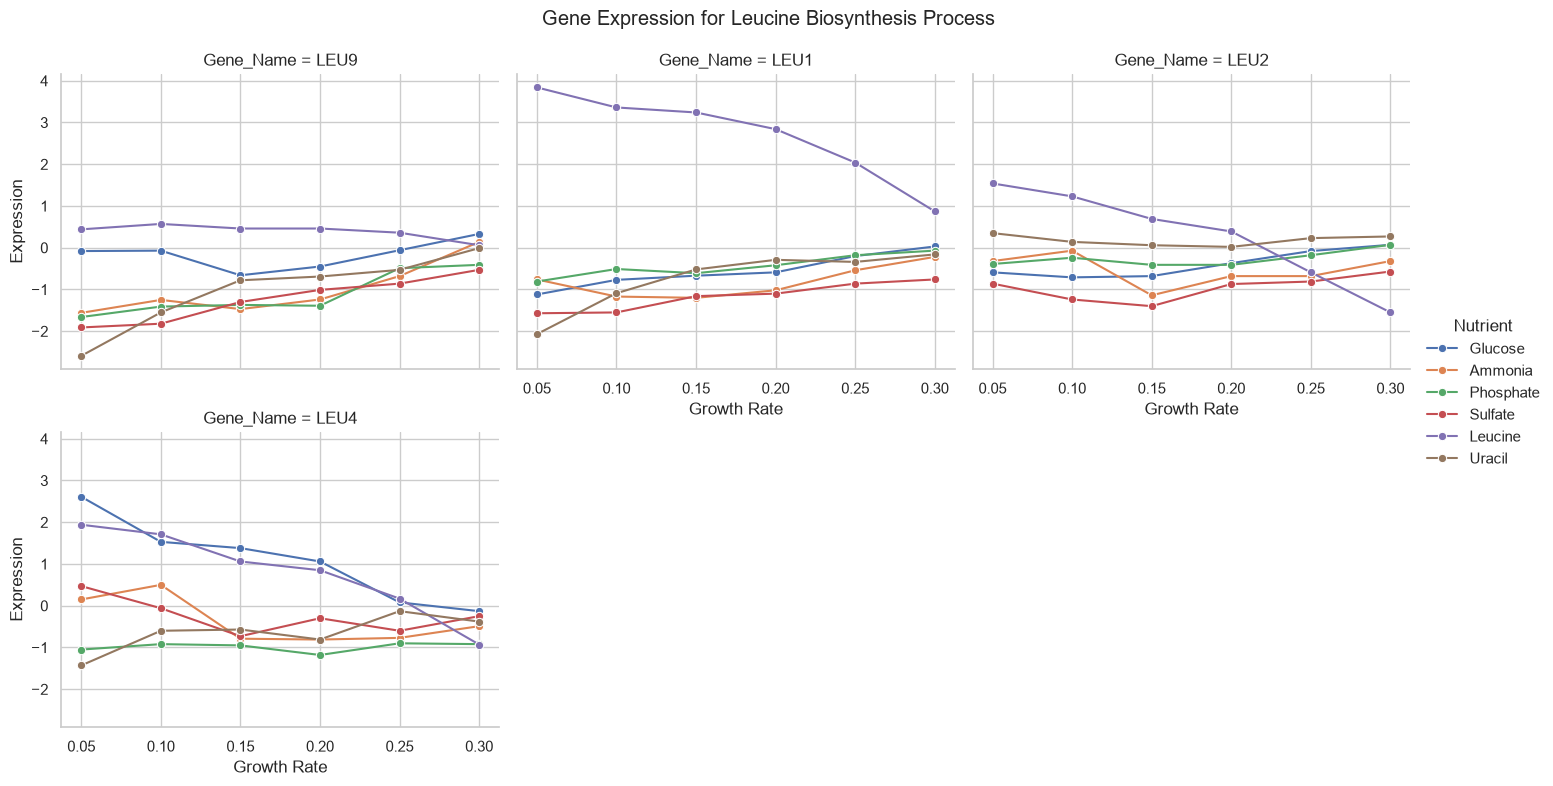

In [8]:

sns.set_theme(style="whitegrid")

df_leu1 = df_tidy[df_tidy['Gene_Name'] == 'LEU1']

plt.figure(figsize=(8, 5))
sns.lineplot(
    data=df_leu1, 
    x='Growth_Rate', 
    y='Expression', 
    hue='Nutrient_Name', 
    marker='o'
)
plt.title("Gene Expression of LEU1 across Growth Rates")
plt.xlabel("Growth Rate")
plt.ylabel("Expression")
plt.legend(title='Nutrient', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


df_bp = df_tidy[df_tidy['Biological_Process'] == 'leucine biosynthesis']

g = sns.FacetGrid(df_bp, col="Gene_Name", col_wrap=3, height=4, aspect=1.2)
g.map_dataframe(sns.lineplot, x="Growth_Rate", y="Expression", hue="Nutrient_Name", marker='o')

g.add_legend(title="Nutrient")
g.set_axis_labels("Growth Rate", "Expression")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("Gene Expression for Leucine Biosynthesis Process")

plt.show()